# Predicting College Graduation Rates
### An applied statistical learning case study

**Research question:** How well do observable institutional characteristics predict graduation rates at US colleges?

This independent portfolio analysis adapts statistical modelling techniques practised in LSE PP422. It is not a reproduction of the original assessed assignment. The analysis explores the data, handles an implausible outcome value, compares linear regression specifications, and evaluates out-of-sample prediction.

**Important:** The associations shown here are descriptive and predictive, **not causal**. The dataset is a historical teaching dataset and is not suitable for evaluating current colleges.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

DATA_PATH = Path("College.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("college-graduation-prediction/College.csv")
colleges = pd.read_csv(DATA_PATH)
print(f"Rows: {len(colleges):,}; columns: {len(colleges.columns)}")
display(colleges.head(3))

Rows: 777; columns: 19


,Name,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54


## 1. Data quality and exploratory analysis

The source has 777 institutions. One recorded graduation rate exceeds 100%, which is not plausible as a percentage. Rather than silently changing its value, we exclude that observation from modelling and report the decision. This differs from fitting the original coursework model to all 777 rows.

In [2]:
print("Missing values:", int(colleges.isna().sum().sum()))
invalid = colleges.loc[~colleges["Grad.Rate"].between(0, 100), ["Name", "Grad.Rate"]]
display(invalid)
clean = colleges.loc[colleges["Grad.Rate"].between(0, 100)].copy()
clean["Private"] = pd.Categorical(clean["Private"], categories=["No", "Yes"])
print("Rows retained for modelling:", len(clean))

Missing values: 0


,Name,Grad.Rate
95,Cazenovia College,118


Rows retained for modelling: 776


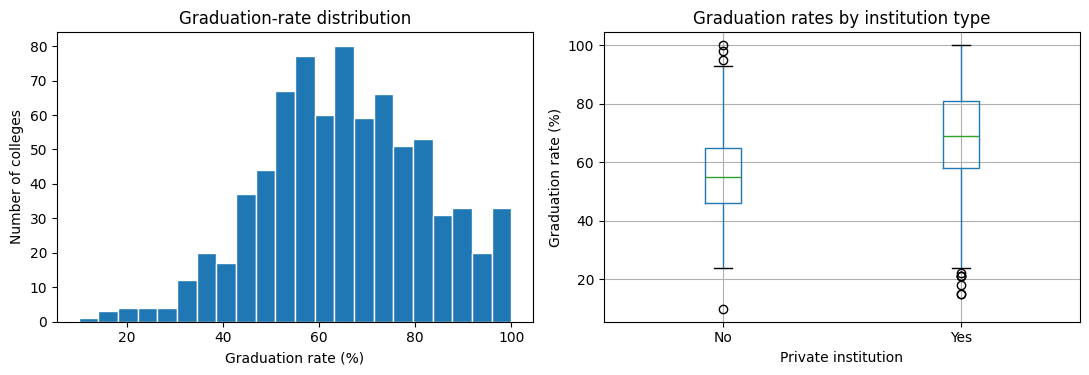

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(clean["Grad.Rate"], bins=22, edgecolor="white")
axes[0].set(xlabel="Graduation rate (%)", ylabel="Number of colleges", title="Graduation-rate distribution")
clean.boxplot(column="Grad.Rate", by="Private", ax=axes[1])
axes[1].set(xlabel="Private institution", ylabel="Graduation rate (%)", title="Graduation rates by institution type")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 2. Train/test design

We reserve 30% of institutions for evaluation. All model choices below are fitted using the training data; the held-out test data is used to compare predictive performance. A single random split gives only one estimate of generalisation performance.

In [4]:
train, test = train_test_split(clean, test_size=0.30, random_state=422)
print(f"Train: {len(train)} | Test: {len(test)}")

Train: 543 | Test: 233


## 3. Linear regression specifications

We compare an eight-predictor OLS model with a smaller, **pre-specified** three-predictor model. We do not select predictors based on test-set results or claim that p-values alone establish predictive usefulness.

In [5]:
full_formula = ('Q("Grad.Rate") ~ C(Private) + Top10perc + Top25perc + PhD '
                '+ Terminal + Q("S.F.Ratio") + Q("perc.alumni") + Expend')
simple_formula = 'Q("Grad.Rate") ~ C(Private) + Top25perc + Q("perc.alumni")'
models = {
    "Full OLS (8 predictors)": smf.ols(full_formula, data=train).fit(),
    "Parsimonious OLS (3 predictors)": smf.ols(simple_formula, data=train).fit(),
}
display(pd.DataFrame({
    "Coefficient": models["Full OLS (8 predictors)"].params.index,
    "Estimate": models["Full OLS (8 predictors)"].params.values,
    "p-value": models["Full OLS (8 predictors)"].pvalues.values,
}).round(4))

,Coefficient,Estimate,p-value
0,Intercept,26.6334,0.0000
1,C(Private)[T.Yes],9.5393,0.0000
2,Top10perc,0.1501,0.0876
3,Top25perc,0.1573,0.0248
4,PhD,0.1271,0.1019
5,Terminal,-0.0241,0.7644
6,"Q(""S.F.Ratio"")",0.2873,0.1695
7,"Q(""perc.alumni"")",0.3055,0.0000
8,Expend,0.0001,0.7812


## 4. Held-out predictive performance

RMSE is expressed in graduation-rate **percentage points**. MAE offers a complementary measure that is less sensitive to large errors. A baseline predicting the training-set mean provides context for interpreting the models.

In [6]:
records = []
predictions = {}
baseline = np.repeat(train["Grad.Rate"].mean(), len(test))
for label, pred in [("Mean baseline", baseline)] + [
    (name, model.predict(test)) for name, model in models.items()
]:
    predictions[label] = np.asarray(pred)
    records.append({
        "Model": label,
        "Test RMSE (pp)": np.sqrt(mean_squared_error(test["Grad.Rate"], pred)),
        "Test MAE (pp)": mean_absolute_error(test["Grad.Rate"], pred),
    })
results = pd.DataFrame(records).sort_values("Test RMSE (pp)")
display(results.round(2))

,Model,Test RMSE (pp),Test MAE (pp)
1,Full OLS (8 predictors),13.28,10.36
2,Parsimonious OLS (3 predictors),13.42,10.55
0,Mean baseline,17.04,13.95


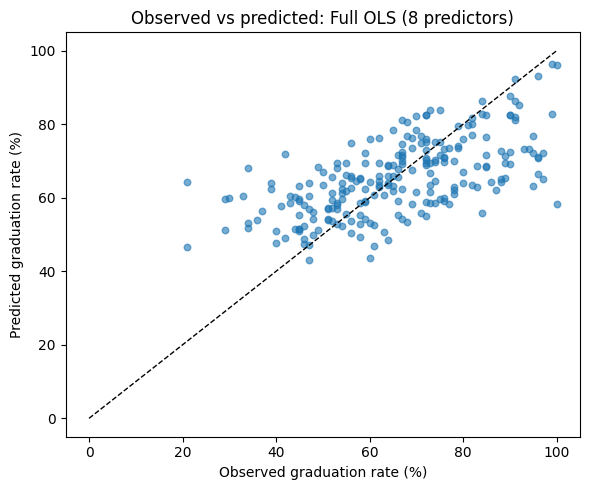

In [7]:
best_name = results.iloc[0]["Model"]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(test["Grad.Rate"], predictions[best_name], alpha=0.6, s=22)
ax.plot([0, 100], [0, 100], linestyle="--", color="black", linewidth=1)
ax.set(xlabel="Observed graduation rate (%)",
       ylabel="Predicted graduation rate (%)",
       title=f"Observed vs predicted: {best_name}")
plt.tight_layout()
plt.show()

## 5. Interpretation and limitations

- Compare test RMSE with the mean-prediction baseline to judge whether institutional characteristics add predictive value.
- Similar test errors for full and parsimonious OLS models suggest that extra predictors may not meaningfully improve performance **on this particular split**.
- The predictors may be correlated, and the relationships are not causal.
- A single train/test split is sensitive to sampling variability; repeated cross-validation is a sensible extension.
- The historical sample, potential selection effects, and limited set of institutional measures constrain generalisation.
- One graduation rate above 100% was excluded rather than overwritten; report this preprocessing decision when comparing results with other analyses.

**Next extension:** Evaluate cross-validated RMSE and investigate regularisation, clearly distinguishing new methods from those implemented in the original PP422 work.